# BIOT 6900 · Module 10 — Notebook 2
## Single-cell and spatial omics with AI

#### Where is ERBB2 expressed in breast cancer?
I followed ERBB2, the gene that encodes HER2, across two breast-cancer datasets. I first asked which cells contribute most of the RNA signal, then checked where the signal falls on an intact tissue section. The Census donors and the Visium specimen are separate samples.

The numerical results and figures are saved below. Each interpretation is an editable Markdown cell.

### Environment
Updated to Python 3.12 environment with the accompanying `biot6900_env.yml` as squidpy requires later version (python 3.11 on't work). On native Windows, open this notebook beside the `cache` folder. It contains the original 20,000-cell Census count matrix used for the saved analysis. On Explorer or macOS, the notebook can also retrieve that sample from the pinned Census release. Scanpy loads the 10x Visium section on first use. The starter trains scVI for 200 epochs on an available CUDA GPU or 60 epochs on CPU.

In [1]:
# Dependencies are installed by biot6900_env.yml before Jupyter starts.
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
from importlib.metadata import PackageNotFoundError, version
import os
import hashlib
from pathlib import Path
from urllib.parse import urlsplit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import torch
from IPython.display import display
from scipy import sparse

SEED = 0
TARGET = "ERBB2"
GPU = torch.cuda.is_available()
sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=95, figsize=(4.2, 3.6), fontsize=9, facecolor="white")
plt.rcParams["figure.max_open_warning"] = 40
pd.set_option("display.max_columns", 12)
print("Target:", TARGET, "| CUDA:", GPU)
package_versions = {pkg: version(pkg) for pkg in ["scanpy", "squidpy", "scvi-tools", "harmonypy", "torch"]}
try:
    package_versions["cellxgene-census"] = version("cellxgene-census")
except PackageNotFoundError:
    package_versions["cellxgene-census"] = "optional for a cached sample"
display(pd.Series(package_versions, name="version").to_frame())

Target: ERBB2 | CUDA: False


,version
scanpy,1.11.5
squidpy,1.8.4
scvi-tools,1.4.3
harmonypy,0.1.0
torch,2.8.0+cpu
cellxgene-census,1.18.0


## 1 · Which cells express ERBB2?
### 1.1 · Sample donors from the Census
I used the starter's exact primary-data filter. Its “whole donor” rule selects eligible donors first, then samples 2,000 cells per selected donor. I pinned the stable release used here. I used the same count matrix for both ways of running Part 1. The Windows bundle includes the original Census export. Without a cache, a supported Linux or macOS environment can run the donor-sampling query below. The notebook checks the release, filter and cell-ID fingerprint when it loads the matrix.

Five donors contributed breast tissue, four contributed liver and one contributed chest wall. I kept the hepatocyte label visible for that reason. I also matched “T cell” as a separate word, since the last letters of “malignant cell” would otherwise send a tumor cell to the T-cell group.

In [3]:
CENSUS_RELEASE = "2025-11-08"
DISEASE_FILTER = "disease == 'breast cancer' and is_primary_data == True"
rng = np.random.default_rng(SEED)
cells_per_donor = 2_000

cache_dir = Path(sc.settings.cachedir)
cache_file = cache_dir / f"census_{CENSUS_RELEASE}_breast_primary_10x2000_seed{SEED}.h5ad"

def fetch_sample():
    # Only a fresh download needs the Census client and its native TileDB libraries.
    try:
        import cellxgene_census
    except (ImportError, OSError) as exc:
        if os.name == "nt":
            raise FileNotFoundError(
                f"The saved Census sample is missing from {cache_file.resolve()}. "
                "Extract the complete Module 8 Windows ZIP and open the notebook beside its cache folder."
            ) from exc
        raise
    # The public S3 reader needs the same proxy as Python on some course networks.
    proxy = urlsplit(os.environ.get("HTTPS_PROXY", ""))
    soma_config = {"sm.compute_concurrency_level": "4", "sm.io_concurrency_level": "16",
                   "soma.init_buffer_bytes": str(16 * 1024**2)}
    if proxy.hostname:
        soma_config.update({"vfs.s3.proxy_host": proxy.hostname,
                            "vfs.s3.proxy_port": str(proxy.port or (443 if proxy.scheme == "https" else 80)),
                            "vfs.s3.proxy_scheme": proxy.scheme})
    if os.getenv("SSL_CERT_FILE"):
        soma_config["vfs.s3.ca_file"] = os.environ["SSL_CERT_FILE"]

    with cellxgene_census.open_soma(census_version=CENSUS_RELEASE, tiledb_config=soma_config) as census:
        obs = cellxgene_census.get_obs(
            census, "Homo sapiens", value_filter=DISEASE_FILTER,
            column_names=["soma_joinid", "donor_id", "assay", "cell_type"],
        )
        donor_sizes = obs["donor_id"].value_counts()
        eligible = donor_sizes[donor_sizes >= cells_per_donor].index.to_numpy()
        if not len(eligible):
            raise ValueError("No eligible donor for this release and filter. Check the Canvas disease label.")
        donors = rng.choice(eligible, size=min(10, len(eligible)), replace=False)
        selected = np.sort(np.concatenate([
            rng.choice(obs.loc[obs["donor_id"] == d, "soma_joinid"].to_numpy(),
                       size=cells_per_donor, replace=False) for d in donors
        ]))
        adata = cellxgene_census.get_anndata(
            census, "Homo sapiens", obs_coords=selected,
            obs_column_names=["donor_id", "assay", "cell_type", "disease", "sex", "tissue_general", "dataset_id"],
            var_column_names=["feature_id", "feature_name"],
        )

    adata.obs["soma_joinid"] = selected
    adata.uns["sampling"] = {
        "release": CENSUS_RELEASE, "filter": DISEASE_FILTER, "seed": SEED, "cells_per_donor": cells_per_donor,
        "requested_donors": 10, "matching_cells": len(obs), "eligible_donors": len(eligible),
        "selection_sha256": hashlib.sha256(selected.astype("<i8").tobytes()).hexdigest(),
    }
    return adata

if cache_file.is_file():
    adata = sc.read_h5ad(cache_file)
else:
    adata = fetch_sample()
    cache_dir.mkdir(parents=True, exist_ok=True)
    adata.write_h5ad(cache_file)
sampling = adata.uns["sampling"]
assert sampling["release"] == CENSUS_RELEASE and sampling["filter"] == DISEASE_FILTER
assert sampling["selection_sha256"] == hashlib.sha256(adata.obs["soma_joinid"].to_numpy(dtype="<i8").tobytes()).hexdigest()

for key in adata.obs.select_dtypes(include="category").columns:
    adata.obs[key] = adata.obs[key].cat.remove_unused_categories()
adata.var_names = adata.var["feature_name"].astype(str)
adata.var_names_make_unique(join="__")
print(f"Release {CENSUS_RELEASE} | {sampling['matching_cells']:,} matching cells | {sampling['eligible_donors']} eligible donors")
print(f"Sampled {adata.n_obs:,} cells | {adata.obs['donor_id'].nunique()} donors")
display(pd.crosstab(adata.obs["donor_id"], adata.obs["assay"], margins=True))
display(adata.obs.groupby("tissue_general", observed=True).agg(cells=("donor_id", "size"), donors=("donor_id", "nunique")))

Release 2025-11-08 | 1,101,430 matching cells | 102 eligible donors
Sampled 20,000 cells | 10 donors


assay,10x 3' v2,10x 3' v3,10x 5' v2,All
donor_id,,,,
HTAPP-211,0,2000,0,2000
HTAPP-313,0,2000,0,2000
HTAPP-516,0,2000,0,2000
HTAPP-806,78,1922,0,2000
HTAPP-889,0,2000,0,2000
HTAPP-997,0,2000,0,2000
QianBRCA_BC_5,0,0,2000,2000
pal_Patient 0056,2000,0,0,2000
pal_Patient 0176,0,2000,0,2000


,cells,donors
tissue_general,,
breast,10000,5
chest wall,2000,1
liver,8000,4


In [4]:
# Census labels such as "malignant cell" and "mast cell" also end in the letters "t cell".
# Include the word boundary when matching lymphocyte names.
def broad_type(label):
    label = str(label).lower()
    if any(s in label for s in ("natural killer", "innate lymphoid")):
        return "NK"
    if (" t cell" in " " + label or
            any(s in label for s in ("cd4", "cd8", "t follicular helper", "thymocyte"))):
        return "T"
    if "plasma cell" in label or "plasmablast" in label or " b cell" in " " + label:
        return "B"
    if "macrophage" in label:
        return "Macrophage"
    if "monocyte" in label:
        return "Monocyte"
    if "dendritic" in label:
        return "DC"
    if any(s in label for s in ("epithel", "luminal", "basal", "carcinoma", "tumor", "malignant")):
        return "Epithelial/Tumor"
    if "hepatocyte" in label:
        return "Hepatocyte"
    if "fibroblast" in label or "stromal" in label:
        return "Fibroblast"
    if "endothel" in label:
        return "Endothelial"
    return "Other"

adata.obs["cell_type_broad"] = adata.obs["cell_type"].astype(str).map(broad_type).astype("category")
display(adata.obs.groupby(["cell_type_broad", "cell_type"], observed=True).size()
        .rename("sampled cells").to_frame())

sampled cells
cell_type_broad  cell_type                                                        
B                B cell                                                        223
                 IgG plasma cell                                                56
                 memory B cell                                                 249
                 plasma cell                                                    44
DC               conventional dendritic cell                                    32
                 myeloid dendritic cell                                          6
                 plasmacytoid dendritic cell                                    14
Endothelial      blood vessel endothelial cell                                 778
                 capillary endothelial cell                                      1
                 endothelial cell                                              313
                 endothelial cell of artery                                      1
                 endothelial cell of hepatic sinusoid                          345
                 endothelial cell of vascular tree                              18
                 vein endothelial cell                                          10
Epithelial/Tumor epithelial cell                                               152
                 malignant cell                                               9616
Fibroblast       fibroblast                                                   1118
                 myofibroblast cell                                             26
Hepatocyte       hepatocyte                                                   2606
Macrophage       cycling macrophage                                             10
                 macrophage                                                   1250
Monocyte         monocyte                                                       73
NK               natural killer cell                                            61
Other            blood vessel smooth muscle cell                               139
                 cell of skeletal muscle                                       135
                 hepatic stellate cell                                         110
                 mast cell                                                      17
                 mononuclear phagocyte                                          58
                 neuron                                                         16
                 pericyte                                                        2
                 vascular associated smooth muscle cell                         10
T                CD4-positive, CD25-positive, CCR4-positive, alp...             81
                 CD8-positive, alpha-beta regulatory T cell                     85
                 T cell                                                       1713
                 T follicular helper cell                                       49
                 cycling T cell                                                 11
                 effector memory CD4-positive, alpha-beta T cell                69
                 effector memory CD8-positive, alpha-beta T cell               197
                 exhausted T cell                                               17
                 mature NK T cell                                               74
                 naive T cell                                                  215

### 1.2 · Quality control, normalization and PCA
I kept the integer counts for scVI and saved the full set of QC-passing genes as log-normalized expression for the marker plots. The donor-specific Seurat v3 fits needed a LOESS span of 0.4 because the default of 0.3 was singular in two donors. The modeling matrix has 2,000 HVGs, while I can still look up ERBB2 in the full expression matrix.

In [5]:
before_qc = adata.obs["donor_id"].value_counts().rename("sampled")
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[(adata.obs["n_genes_by_counts"] < 6000) & (adata.obs["pct_counts_mt"] < 15)].copy()
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat_v3", span=0.4,
                            layer="counts", batch_key="donor_id")
adata = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=30, svd_solver="arpack", random_state=SEED)
qc = pd.concat([before_qc, adata.obs["donor_id"].value_counts().rename("retained")], axis=1)
qc["retained %"] = (100 * qc["retained"] / qc["sampled"]).round(1)
display(qc.sort_index())
print(f"{adata.n_obs:,} cells after QC | {adata.n_vars:,} HVGs | {adata.raw.n_vars:,} genes for expression")

18,388 cells after QC | 2,000 HVGs | 27,400 genes for expression


/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


,sampled,retained,retained %
donor_id,,,
HTAPP-211,2000,1971,98.6
HTAPP-313,2000,1516,75.8
HTAPP-516,2000,1843,92.2
HTAPP-806,2000,1953,97.6
HTAPP-889,2000,1869,93.4
HTAPP-997,2000,1855,92.8
QianBRCA_BC_5,2000,2000,100.0
pal_Patient 0056,2000,1980,99.0
pal_Patient 0176,2000,1689,84.4


### 1.3 · Donor structure before integration
These panels use identical UMAP coordinates. I can follow a patch from the donor panel to the broad-label panel and see what changed when I switched the colors.

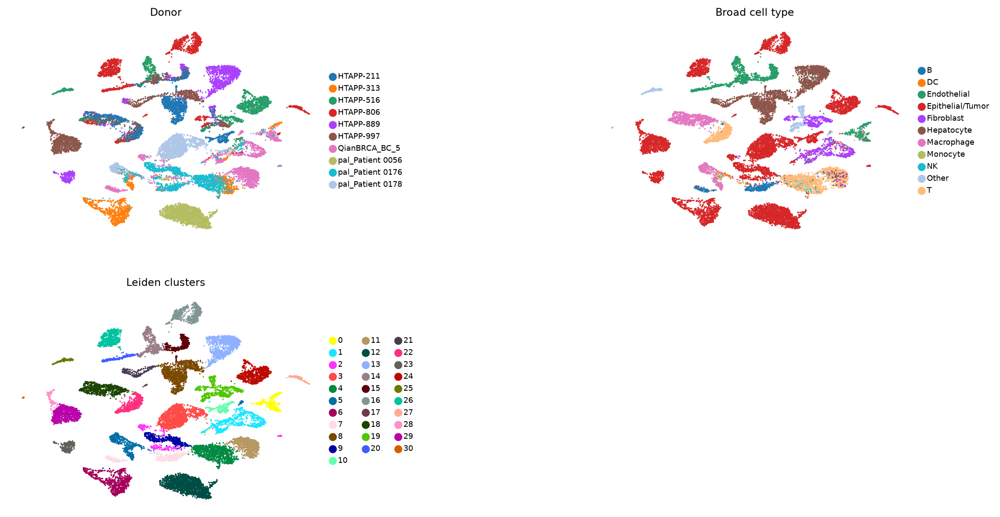

In [6]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca", random_state=SEED)
sc.tl.leiden(adata, resolution=0.6, key_added="leiden_unintegrated", random_state=SEED,
             flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata, random_state=SEED)
adata.obsm["X_umap_unint"] = adata.obsm["X_umap"].copy()
sc.pl.embedding(adata, basis="umap_unint", color=["donor_id", "cell_type_broad", "leiden_unintegrated"],
                title=["Donor", "Broad cell type", "Leiden clusters"], ncols=2, wspace=0.7,
                legend_fontsize=7, frameon=False)

**Reading the unintegrated map.** Several islands at the bottom and on the left all carry the epithelial/tumor label, yet each is dominated by a different donor. T cells form a more recognizable group on the lower right, so I see both cell identity and donor structure before integration.

### 1.4 · Integrate the count matrix with scVI

In [7]:
import scvi

scvi.settings.seed = SEED
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="donor_id")
vae = scvi.model.SCVI(adata, n_latent=30)
epochs = 200 if GPU else 60
vae.train(max_epochs=epochs, accelerator="gpu" if GPU else "cpu", devices=1,
          enable_progress_bar=False, enable_model_summary=False)
adata.obsm["X_scVI"] = vae.get_latent_representation()
print(f"scVI: {epochs} epochs on {'GPU' if GPU else 'CPU'} | latent matrix {adata.obsm['X_scVI'].shape}")

scVI: 60 epochs on CPU | latent matrix (18388, 30)


Seed set to 0
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/workspace/scratch/60fc5dd44669/work/omx/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=8` in the `DataLoader` to improve performance.
`Trainer.fit` stopped: `max_epochs=60` reached.


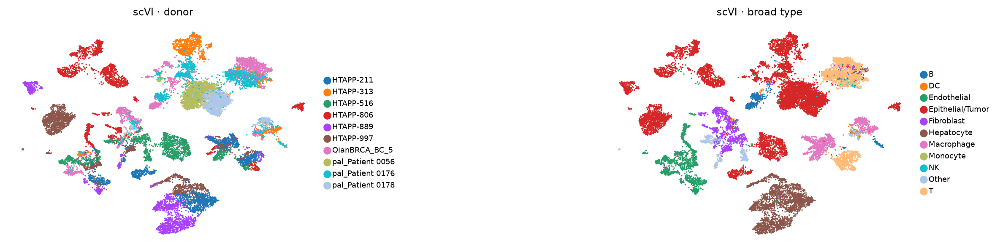

In [8]:
def integrated_umap(representation, basis, name):
    sc.pp.neighbors(adata, n_neighbors=15, use_rep=representation, random_state=SEED)
    sc.tl.umap(adata, random_state=SEED)
    adata.obsm["X_" + basis] = adata.obsm["X_umap"].copy()
    sc.pl.embedding(adata, basis=basis, color=["donor_id", "cell_type_broad"],
                    title=[name + " · donor", name + " · broad type"], wspace=0.75,
                    legend_fontsize=7, frameon=False)

integrated_umap("X_scVI", "umap_scvi", "scVI")

**Did the donors mix?** The upper-right T-cell group includes several donor colors. Some epithelial/tumor islands, especially on the left, are still dominated by one donor. Given the sample sites and the uneven use of assays, I would be cautious about trying to remove every one of those differences.

### 1.5 · Compare Harmony on the same starting PCs

2026-11-19 23:29:17,839 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-19 23:29:18,331 - harmonypy - INFO - KMeans initialization complete.


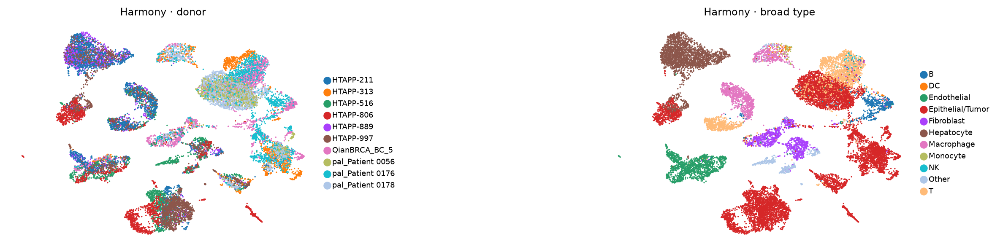

In [9]:
import harmonypy

fit = harmonypy.run_harmony(adata.obsm["X_pca"].astype(np.float64), adata.obs, "donor_id",
                            random_state=SEED, verbose=False)
z = np.asarray(fit.Z_corr)
adata.obsm["X_pca_harmony"] = (z if z.shape[0] == adata.n_obs else z.T).astype("float32")
integrated_umap("X_pca_harmony", "umap_harmony", "Harmony")

### 1.6 · Compare donor mixing and broad-label separation
I scored the same cells in each 30-dimensional representation before projecting to UMAP. The donor score is the starter's signed silhouette. A value near zero means there is little donor separation on average. A higher cell-type silhouette favors better separation of the supplied broad labels.

In [10]:
from sklearn.metrics import silhouette_score

idx = np.random.default_rng(SEED).choice(adata.n_obs, size=min(5_000, adata.n_obs), replace=False)
reps = {"No integration": "X_pca", "Harmony": "X_pca_harmony", "scVI": "X_scVI"}
score_rows = []
for name, rep in reps.items():
    emb = adata.obsm[rep][idx]
    donor_asw = silhouette_score(emb, adata.obs["donor_id"].iloc[idx])
    type_asw = silhouette_score(emb, adata.obs["cell_type_broad"].iloc[idx])
    score_rows.append((name, donor_asw, type_asw))
scores = pd.DataFrame(score_rows, columns=["Method", "Donor silhouette", "Broad-type silhouette"]).set_index("Method")
print(f"{len(idx):,} cells | {adata.obsm['X_pca'].shape[1]} dimensions per method")
display(scores.round(4))

5,000 cells | 30 dimensions per method


,Donor silhouette,Broad-type silhouette
Method,,
No integration,0.1210,0.0130
Harmony,-0.0937,0.0472
scVI,-0.0258,0.0569


**Which integration would I use?** I would use scVI for the final map. It had the highest broad-type silhouette (0.0569 versus 0.0472 for Harmony and 0.0130 before correction) and the donor score closest to zero (−0.0258). Harmony wins on the starter’s lower-is-better signed donor score (−0.0937 versus −0.0258). A negative value means a cell can be closer to another donor than to its own, so I also considered the distance from zero and looked at the marker patterns. The broad-label advantage of 0.0097 is modest on a single subsample. I would keep Harmony as a credible, cheaper alternative.

### 1.7 · Check the labels against canonical markers
The dots give two different pieces of information. Their size is the percentage of cells with detectable RNA. Their color is mean log-normalized expression over all cells in that group.

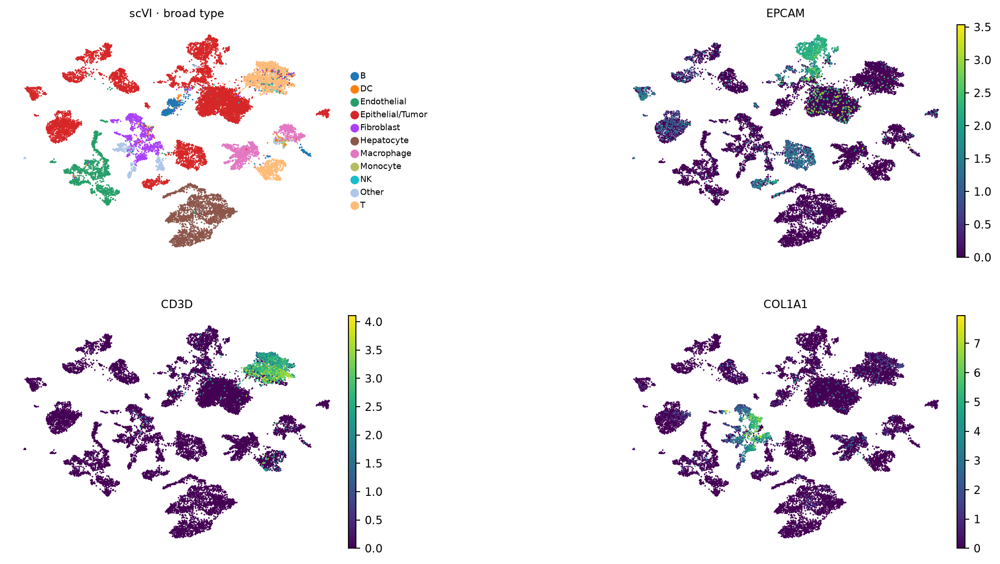

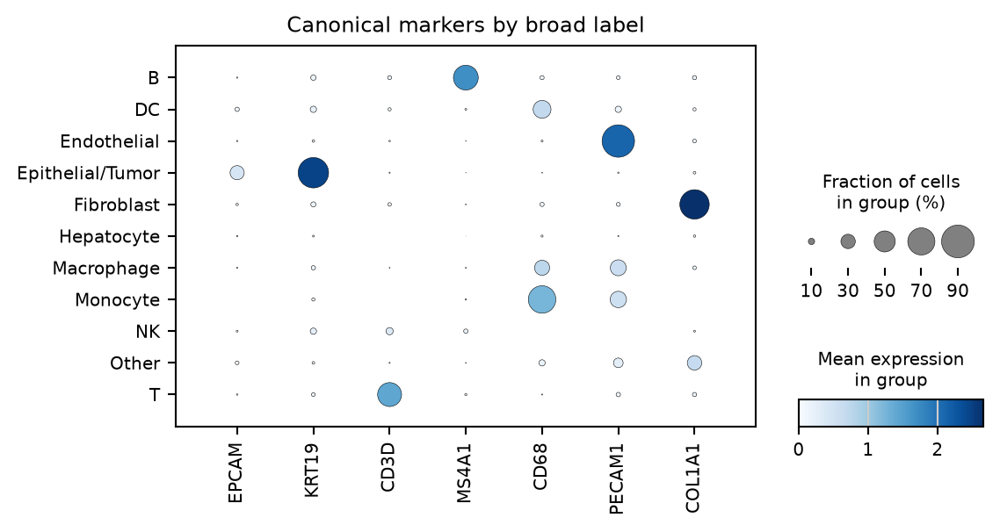

In [11]:
corrected = scores.loc[["Harmony", "scVI"]]
chosen_method = (corrected["Broad-type silhouette"] - corrected["Donor silhouette"].abs()).idxmax()
basis = {"scVI": "umap_scvi", "Harmony": "umap_harmony", "No integration": "umap_unint"}[chosen_method]
markers = [g for g in ["EPCAM", "KRT19", "CD3D", "MS4A1", "CD68", "PECAM1", "COL1A1"]
           if g in adata.raw.var_names]
sc.pl.embedding(adata, basis=basis, color=["cell_type_broad", "EPCAM", "CD3D", "COL1A1"],
                title=[chosen_method + " · broad type", "EPCAM", "CD3D", "COL1A1"],
                use_raw=True, ncols=2, wspace=0.65, legend_fontsize=7, frameon=False)
sc.pl.dotplot(adata, var_names=markers, groupby="cell_type_broad", use_raw=True,
              cmap="Blues", figsize=(6.2, 3.0), title="Canonical markers by broad label")

**Checking the annotations.** CD3D aligns with the T-cell group and COL1A1 with fibroblasts. In the epithelial/tumor group, KRT19 has a much larger, darker dot than EPCAM. That supports the epithelial annotation even though EPCAM is only detectable in a subset of those cells. All of these checks use expression measured before integration.

### 1.8 · Locate ERBB2 in individual cells
I compared detection rates and mean expression. An abundant cell type can contribute many positive cells even when only a small fraction of its own cells express the gene.

,cells,donors,positive,mean_log,detected_%
cell_type_broad,,,,,
Epithelial/Tumor,8678,10,3155,0.633,36.356
DC,50,3,8,0.262,16.000
NK,50,1,5,0.258,10.000
Hepatocyte,2473,4,466,0.207,18.844
B,515,4,35,0.127,6.796
Fibroblast,1096,10,105,0.114,9.580
Other,478,7,34,0.089,7.113
T,2355,8,66,0.062,2.803
Macrophage,1189,9,36,0.048,3.028


,cells,positive,detected_fraction
donor_id,,,
pal_Patient 0056,1963,95,0.048
HTAPP-806,1421,478,0.336
pal_Patient 0178,1416,38,0.027
HTAPP-997,1021,749,0.734
HTAPP-313,776,721,0.929
HTAPP-516,758,385,0.508
pal_Patient 0176,563,374,0.664
QianBRCA_BC_5,271,103,0.380
HTAPP-889,248,169,0.681


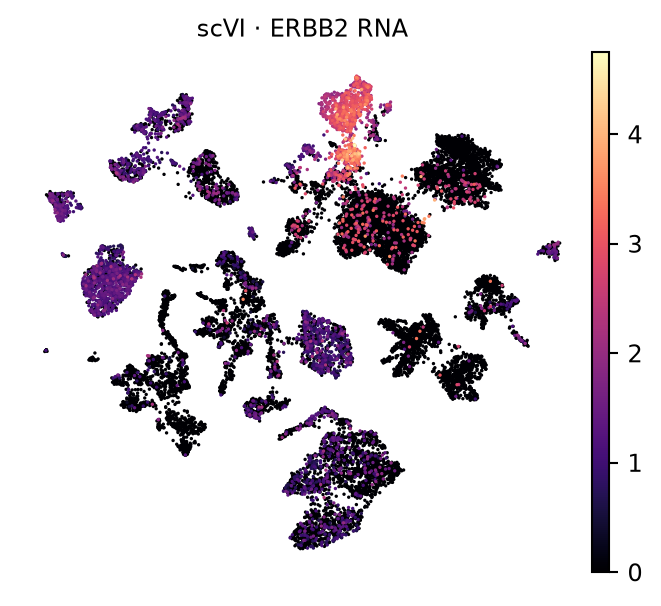

In [12]:
def expression_vector(raw, gene):
    column = raw[:, gene].X
    return column.toarray().ravel() if sparse.issparse(column) else np.asarray(column).ravel()

single_expr = adata.obs[["donor_id", "cell_type_broad"]].copy()
single_expr["log_expression"] = expression_vector(adata.raw, TARGET)
single_expr["detected"] = single_expr["log_expression"] > 0
by_type = single_expr.groupby("cell_type_broad", observed=True).agg(
    cells=("detected", "size"), donors=("donor_id", "nunique"), positive=("detected", "sum"),
    mean_log=("log_expression", "mean"))
by_type["detected_%"] = 100 * by_type["positive"] / by_type["cells"]
by_type = by_type.sort_values("mean_log", ascending=False)
display(by_type.round(3))
by_donor = single_expr.groupby(["cell_type_broad", "donor_id"], observed=True).agg(
    cells=("detected", "size"), positive=("detected", "sum"), detected_fraction=("detected", "mean"))
display(by_donor.loc[by_type.index[0]].sort_values("cells", ascending=False).round(3))
sc.pl.embedding(adata, basis=basis, color=TARGET, use_raw=True, cmap="magma", sort_order=True,
                frameon=False, title=chosen_method + " · " + TARGET + " RNA")

**Which cells account for the signal?** The epithelial/tumor group had the highest mean ERBB2 expression (about 0.63 log-normalized units) and detection rate (3,155/8,678, or 36.4%). I also saw ERBB2 in 18.8% of hepatocytes from the liver samples, compared with 2.8% of T cells and 3.0% of macrophages. Even within epithelial/tumor cells, detection ranged from 2.7% in pal_Patient 0178 to 92.9% in HTAPP-313. That range matters if I am trying to describe an individual tumor.

## 2 · Where is ERBB2 in the tissue?
### 2.1 · The assigned Visium section
I started with the H&E image so I could see which parts of the section the capture spots actually cover.

V1_Breast_Cancer_Block_A_Section_1 | 3,798 in-tissue spots × 36,601 features


/workspace/scratch/60fc5dd44669/work/omx/lib/python3.12/site-packages/scanpy/readwrite.py:310: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  return AnnData(matrix, obs=obs_dict, var=var_dict)
/workspace/scratch/60fc5dd44669/work/omx/lib/python3.12/site-packages/scanpy/readwrite.py:236: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


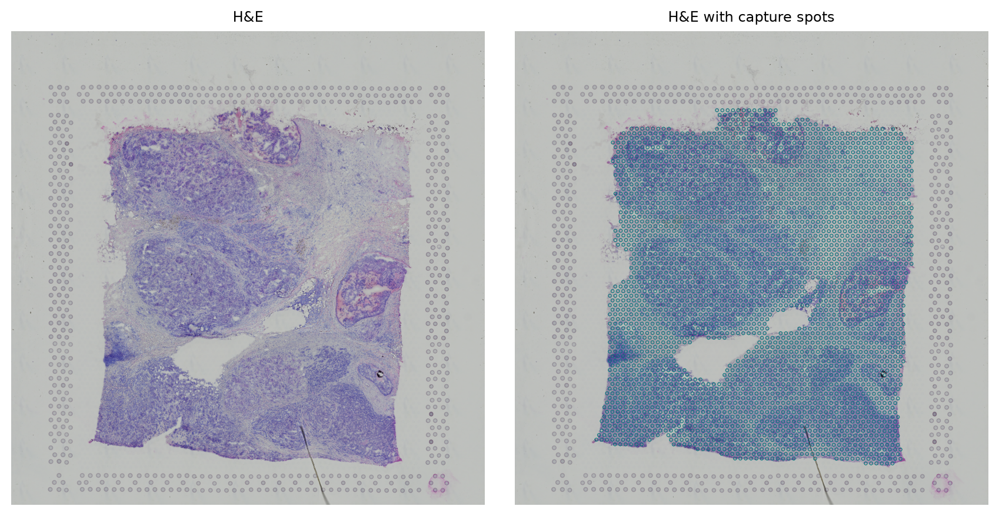

In [13]:
SAMPLE = "V1_Breast_Cancer_Block_A_Section_1"
spatial = sc.datasets.visium_sge(sample_id=SAMPLE)
spatial.var_names_make_unique()
print(f"{SAMPLE} | {spatial.n_obs:,} in-tissue spots × {spatial.n_vars:,} features")
image_info = next(iter(spatial.uns["spatial"].values()))
he = image_info["images"]["hires"]
scale = image_info["scalefactors"]["tissue_hires_scalef"]
xy = spatial.obsm["spatial"] * scale
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5), constrained_layout=True)
for ax, title in zip(axs, ["H&E", "H&E with capture spots"]):
    ax.imshow(he)
    ax.set_title(title)
    ax.set_axis_off()
axs[1].scatter(xy[:, 0], xy[:, 1], s=4, facecolors="none", edgecolors="#05737a", linewidths=0.42)
plt.show()

### 2.2 · Cluster spots by their expression profiles
Clustering uses neighbors in gene-expression space. In sections 2.4–2.6 I build a second graph from the spots' physical coordinates.

In [14]:
n_initial = spatial.n_obs
spatial.var["mt"] = spatial.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(spatial, qc_vars=["mt"], percent_top=None, inplace=True)
sc.pp.filter_cells(spatial, min_counts=500)
spatial.layers["counts"] = spatial.X.copy()
sc.pp.normalize_total(spatial, target_sum=1e4)
sc.pp.log1p(spatial)
spatial.raw = spatial
sc.pp.highly_variable_genes(spatial, n_top_genes=2000)
sc.pp.pca(spatial, random_state=SEED)
sc.pp.neighbors(spatial, random_state=SEED)
sc.tl.leiden(spatial, resolution=0.6, key_added="cluster", random_state=SEED,
             flavor="igraph", n_iterations=2, directed=False)
print(f"{n_initial:,} loaded | {spatial.n_obs:,} retained | {spatial.obs['cluster'].nunique()} Leiden domains")

3,798 loaded | 3,798 retained | 9 Leiden domains


### 2.3 · Read the domains against independent markers
I used epithelial, stromal and immune markers to interpret the cluster IDs. ERBB2 is excluded from these panels so it can be tested independently. Each marker is standardized across spots before the panel mean is calculated. I left a domain mixed when its top score was nonpositive or the two highest domain scores differed by less than 0.15. I also flagged stromal domains with both stromal and immune scores above 0.5 to check for mixed immune–stromal regions.

In [15]:
panels = {"Epithelial-rich": ["EPCAM", "KRT8", "KRT18", "KRT19"],
          "Stromal-rich": ["COL1A1", "COL1A2", "DCN", "LUM"],
          "Immune-rich": ["PTPRC", "CD3D", "MS4A1", "LST1", "CD79A"]}
panel_genes = sum(panels.values(), [])
marker_values = pd.DataFrame(spatial[:, panel_genes].X.toarray(),
                             index=spatial.obs_names, columns=panel_genes)
standardized = (marker_values - marker_values.mean()) / marker_values.std(ddof=0)
spot_scores = pd.DataFrame({label: standardized[genes].mean(axis=1) for label, genes in panels.items()})
domain_scores = spot_scores.groupby(spatial.obs["cluster"], observed=True).mean()
ordered = np.sort(domain_scores.to_numpy(), axis=1)
domain_labels = domain_scores.idxmax(axis=1).mask((ordered[:, -1] <= 0) |
                                                  (ordered[:, -1] - ordered[:, -2] < 0.15), "Mixed")
immune_stroma = (domain_labels == "Stromal-rich") & (domain_scores["Stromal-rich"] > 0.5) & (domain_scores["Immune-rich"] > 0.5)
domain_labels = domain_labels.mask(immune_stroma, "Immune-rich stroma")
spatial.obs["compartment"] = spatial.obs["cluster"].astype(str).map(domain_labels).astype("category")
domain_table = domain_scores.copy()
domain_table.insert(0, "spots", spatial.obs["cluster"].value_counts())
domain_table["working label"] = domain_labels
display(domain_table.round(2))

,spots,Epithelial-rich,Stromal-rich,Immune-rich,working label
cluster,,,,,
0,682,-0.86,0.96,0.65,Immune-rich stroma
1,724,-0.10,0.28,0.05,Stromal-rich
2,474,0.64,0.13,-0.23,Epithelial-rich
3,401,0.56,-0.27,-0.27,Epithelial-rich
4,364,0.31,-0.61,-0.03,Epithelial-rich
5,360,-0.07,-0.80,-0.34,Mixed
6,433,-0.00,-0.49,-0.18,Mixed
7,198,-0.08,-0.09,-0.06,Mixed
8,162,0.36,-0.42,-0.23,Epithelial-rich


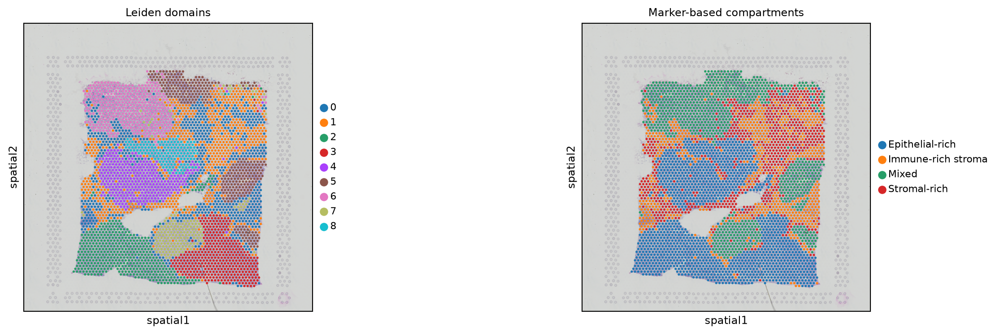

In [16]:
sq.pl.spatial_scatter(spatial, color=["cluster", "compartment"], img_alpha=0.67, size=1.1,
                      title=["Leiden domains", "Marker-based compartments"], ncols=2,
                      figsize=(4.8, 4.4), wspace=0.45)
plt.show()

**Where the domains sit.** Domains 2 and 3 cover large epithelial-rich regions toward the lower left and lower right, and domain 4 covers a rounded region left of center. Domain 0 had the highest immune score (+0.65) along with a stronger stromal score (+0.96). I read it as immune-rich stroma. Domain 1 is more predominantly stromal, and the marker evidence leaves domains 5–7 mixed. The H&E and epithelial markers support a tumor-rich interpretation for several nests, while the distinction between invasive and in situ tissue needs a pathology annotation.

### 2.4 · Which genes have a spatial pattern?
I ranked the spatial HVGs and included ERBB2 even if it missed that list. In this ranking, a large positive Moran's I means that nearby spots have similar expression for that gene.

INFO     Creating graph using `None` transform and `1` libraries.               
2,001 genes ranked | 11,032 undirected first-ring spatial edges


,I
MGP,0.8685
MALAT1,0.7625
CRISP3,0.7263
CPB1,0.7110
IGHG3,0.7038
IGLC2,0.7003
IGKC,0.6807
ALB,0.6679


,I,rank
ERBB2,0.2365,164


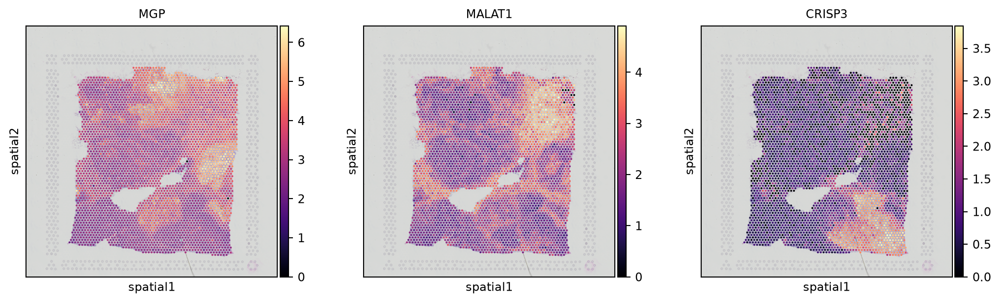

In [17]:
sq.gr.spatial_neighbors(spatial, coord_type="grid", n_neighs=6, n_rings=1)
graph = spatial.obsp["spatial_connectivities"].tocsr()
graph = graph.maximum(graph.T)
graph.setdiag(0)
graph.eliminate_zeros()
moran_genes = spatial.var_names[spatial.var["highly_variable"]].union([TARGET], sort=False).tolist()
sq.gr.spatial_autocorr(spatial, genes=moran_genes, mode="moran", n_jobs=1, show_progress_bar=False)
moran = spatial.uns["moranI"].sort_values("I", ascending=False)
top_moran = moran.head(8)[["I"]]
print(f"{len(moran):,} genes ranked | {graph.nnz // 2:,} undirected first-ring spatial edges")
display(top_moran.round(4))
display(moran.loc[[TARGET], ["I"]].assign(rank=moran.index.get_loc(TARGET) + 1).round(4))
sq.pl.spatial_scatter(spatial, color=top_moran.index[:3].tolist(), cmap="magma", img_alpha=0.6,
                      size=1.05, ncols=3, figsize=(3.5, 3.5), wspace=0.22)
plt.show()

**What the top genes show.** MGP (I = 0.869), MALAT1 (0.763) and CRISP3 (0.726) lead the ranking and have different hotspots. CRISP3 is concentrated at the lower right, MALAT1 toward the upper right, and MGP has bright areas near the top and midway down the right side. ERBB2 also shows spatial structure, with a smaller I of 0.237 and rank 164 out of 2,001 genes tested.

### 2.5 · Which domains meet?
Squidpy counts neighboring domain labels and compares them with 1,000 permutations of those labels on the same spot graph. I checked cross-domain pairs separately because the diagonals mainly describe the interiors of large domains.

,A,B,label A,label B,contacts,z
0,0,1,Immune-rich stroma,Stromal-rich,866,4.64
29,4,8,Epithelial-rich,Epithelial-rich,51,-4.31
6,0,7,Immune-rich stroma,Mixed,115,-7.41
35,7,8,Mixed,Epithelial-rich,1,-7.58
14,1,8,Stromal-rich,Epithelial-rich,88,-7.61
33,6,7,Mixed,Mixed,48,-7.99


,A,B,label A,label B,contacts,z
3,0,4,Immune-rich stroma,Epithelial-rich,115,-15.39
1,0,2,Immune-rich stroma,Epithelial-rich,71,-22.28
2,0,3,Immune-rich stroma,Epithelial-rich,62,-19.35
7,0,8,Immune-rich stroma,Epithelial-rich,56,-9.62


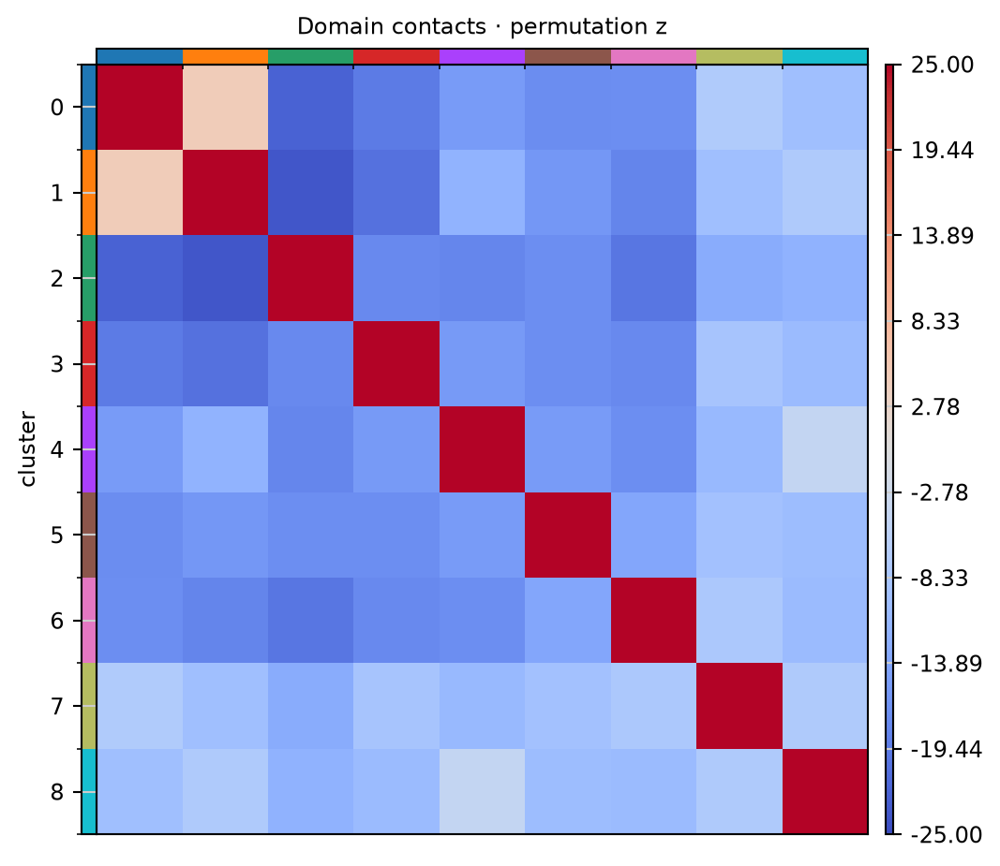

In [18]:
from itertools import combinations

sq.gr.nhood_enrichment(spatial, cluster_key="cluster", n_perms=1000, seed=SEED,
                       n_jobs=1, show_progress_bar=False)
enrichment = spatial.uns["cluster_nhood_enrichment"]
clusters = spatial.obs["cluster"].cat.categories
pairs = []
for i, j in combinations(range(len(clusters)), 2):
    a, b = clusters[i], clusters[j]
    pairs.append((a, b, domain_labels.loc[a], domain_labels.loc[b],
                  int(enrichment["count"][i, j]), float(enrichment["zscore"][i, j])))
pairs = pd.DataFrame(pairs, columns=["A", "B", "label A", "label B", "contacts", "z"])
pairs = pairs.sort_values("z", ascending=False)
display(pairs.head(6).round(2))
tumor_immune = pairs[((pairs["label A"] == "Epithelial-rich") & pairs["label B"].str.startswith("Immune-rich")) |
                     ((pairs["label B"] == "Epithelial-rich") & pairs["label A"].str.startswith("Immune-rich"))]
display(tumor_immune.sort_values("contacts", ascending=False).head(6).round(2))
sq.pl.nhood_enrichment(spatial, cluster_key="cluster", mode="zscore", cmap="coolwarm",
                       vmin=-25, vmax=25, figsize=(5.5, 4.5), title="Domain contacts · permutation z")
plt.show()

**Where does tumor meet immune-rich tissue?** The only enriched pair of different domains was 0–1, with 866 contacts (z = +4.64). Both contain stroma. The immune-rich stromal domain 0 also touched epithelial domain 4 along 115 edges, fewer than expected under shuffled labels (z = −15.39). I can see an epithelial–immune/stromal boundary, although none of the four epithelial domains preferentially touches domain 0 under this null model.

### 2.6 · Test the core, boundary and immune-niche explanations
An epithelial **interior** spot has six observed neighbors, all in epithelial-rich domains. An epithelial **boundary** spot touches at least one observed non-epithelial compartment. If all observed neighbors are epithelial but the ring is incomplete, I keep the spot in a separate edge group. The “boundary” is an expression-defined interface. Confirming invasion would require a pathologist to trace it on the H&E.

Top-decile threshold: 1.882 log1p normalized counts


,spots,positive,mean_log,median_log,high_spots,high_within_zone_%
zone,,,,,,
Epithelial interior,936,935,1.576,1.587,153,16.346
Epithelial boundary,373,368,1.501,1.544,46,12.332
Mixed,991,958,1.367,1.406,66,6.660
"Epithelial, incomplete ring",92,91,1.340,1.392,1,1.087
Stromal-rich,724,564,1.181,1.409,96,13.260
Immune-rich stroma,682,584,0.995,1.090,18,2.639


,,spots,mean_log,high_spots
cluster,compartment,,,
4,Epithelial-rich,364,1.677,96
3,Epithelial-rich,401,1.641,80
8,Epithelial-rich,162,1.529,16
7,Mixed,198,1.414,10
6,Mixed,433,1.388,40
2,Epithelial-rich,474,1.354,8
5,Mixed,360,1.315,16
1,Stromal-rich,724,1.181,96
0,Immune-rich stroma,682,0.995,18


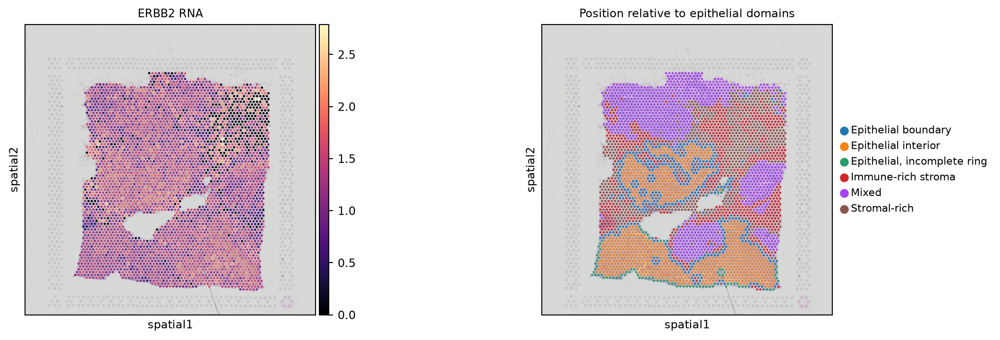

In [19]:
epithelial = spatial.obs["compartment"].eq("Epithelial-rich").to_numpy()
n_neighbors = np.diff(graph.indptr)
n_epithelial = np.asarray((graph != 0).astype(int) @ epithelial.astype(int)).ravel()
zone = spatial.obs["compartment"].astype(str).to_numpy(dtype=object)
zone[epithelial] = "Epithelial, incomplete ring"
zone[epithelial & (n_neighbors > n_epithelial)] = "Epithelial boundary"
zone[epithelial & (n_neighbors == 6) & (n_epithelial == 6)] = "Epithelial interior"
spatial.obs["zone"] = pd.Categorical(zone)

spot_expr = spatial.obs[["cluster", "compartment", "zone"]].copy()
spot_expr["log_expression"] = expression_vector(spatial.raw, TARGET)
spot_expr["detected"] = spot_expr["log_expression"] > 0
cutoff = spot_expr["log_expression"].quantile(0.9)
spot_expr["high"] = spot_expr["log_expression"] >= cutoff
zone_summary = spot_expr.groupby("zone", observed=True).agg(
    spots=("high", "size"), positive=("detected", "sum"), mean_log=("log_expression", "mean"),
    median_log=("log_expression", "median"), high_spots=("high", "sum"))
zone_summary["high_within_zone_%"] = 100 * zone_summary["high_spots"] / zone_summary["spots"]
print(f"Top-decile threshold: {cutoff:.3f} log1p normalized counts")
display(zone_summary.sort_values("mean_log", ascending=False).round(3))
display(spot_expr.groupby(["cluster", "compartment"], observed=True)
        .agg(spots=("high", "size"), mean_log=("log_expression", "mean"), high_spots=("high", "sum"))
        .sort_values("mean_log", ascending=False).round(3))
sq.pl.spatial_scatter(spatial, color=[TARGET, "zone"], use_raw=True, cmap="magma", img_alpha=0.60,
                      size=1.05, ncols=2, figsize=(4.6, 4.2), wspace=0.42,
                      title=[TARGET + " RNA", "Position relative to epithelial domains"])
plt.show()

**Where is ERBB2 strongest?** ERBB2 was detectable in 3,500/3,798 spots, so I compared the fraction of each region in the top tenth. That was 153/936 (16.3%) in epithelial interiors, 46/373 (12.3%) at epithelial boundaries and 18/682 (2.6%) in immune-rich stroma. My best read is that high ERBB2 favors the interior of epithelial nests. There is still signal at their edges and in stromal domain 1 (96/724 high). A cluster boundary alone cannot identify the invasive front.

## 3 · Connecting the two views

Across the Census donors, epithelial/tumor cells accounted for roughly four in five ERBB2-positive cells. In a separate breast-cancer specimen, high ERBB2 occurred most frequently inside epithelial-rich domains. That gives me a plausible cellular source and a tissue location. Because a Visium spot captures multiple cells and the samples are unmatched, I cannot assign a particular spot to one of the Census cells.

The 10x specimen is reported as HER2-positive and includes both in situ and invasive carcinoma. I would compare an interior hotspot, a boundary and an ERBB2-high stromal spot on registered H&E and HER2 IHC sections, with ISH where indicated. Sparse single-cell counts, uneven donor/site representation, broad labels, the spatial marker shortlist and the absence of cell-level segmentation all limit how far I can take the RNA result. [10x specimen description](https://www.10xgenomics.com/datasets/human-breast-cancer-block-a-section-1-1-standard-1-1-0) · [ASCO/CAP HER2 testing algorithm](https://documents.cap.org/documents/her2_breast_update_algorithms_2023.pdf)

***AI assitance has been used for code assistance***